# Argentina vs Egypt: Comeback Rarity and Officiating-Impact Analysis

## Research notebook and reproducible analysis

This notebook operationalizes `Project.md` for Argentina 3-2 Egypt in the 2026 FIFA World Cup Round of 16. It separates observed facts, historical rarity, conditional alternate-state sensitivity, and decision correctness.

## tl;dr

- In the 1930-2022 men's World Cup baseline, no team trailing by at least two goals at minute 70 or 75 went on to win in regulation. Argentina occupied that state in 2026.
- A scenario-only timing grid asks what changes if Egypt's reported disallowed effort creates a 0-2 state at minute 58, 62, or 67. It does **not** assess whether allowing that goal was correct.
- The calibrated gradient-boosting model passes the current engineering gate, but focal probabilities remain exploratory where the time/score/strength neighborhood has low historical support.
- Aggregate card and penalty counts remain descriptive. They cannot identify preferential treatment, corruption, or intent.

## Research contract, evidence standard, and non-negotiable guardrails

**Focal match:** Argentina 3-2 Egypt, FIFA World Cup 2026 Round of 16, Atlanta Stadium, 7 July 2026.

**Primary outcome:** regulation-time result (`ARG_WIN`, `DRAW`, or `EGY_WIN`). Advancement is a separate secondary outcome because it may include extra time and penalties.

**Primary rarity estimand:** for each pre-registered threshold `t in {70, 75, 78, 80}`, estimate `P(regulation win | trailing by at least two at t)` from one reconstructed snapshot per match. Always report numerator, denominator, and uncertainty.

**Decision-impact estimand:** `P(ARG win | observed post-decision state) - P(ARG win | validated alternate state)`. This is conditional on the alternate state and describes modelled outcome sensitivity. It does not determine whether the actual decision was correct or why it was made.

**Evidence tiers:** official match/event documents and referee material are Tier A; time-aligned match video is Tier B; qualified independent technical analysis is Tier C; reporting and public reactions identify claims only. Each material record needs a source URL, retrieval date, source tier, and evidence status.

**Interpretation limits:** a low probability is not proof of manipulation. Public data cannot identify a referee's or institution's intent. Do not sum incident-level effects into a causal "advantage index": incidents may overlap, change later states, and interact.


In [1]:
from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path
from typing import Iterable
import hashlib
import json
import math
import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RANDOM_SEED = 20260707
rng = np.random.default_rng(RANDOM_SEED)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "Project.md").exists() and (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Could not locate the project root from the active notebook directory.")

PROJECT_ROOT = find_project_root(Path.cwd())
DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
MANIFESTS_DIR = PROJECT_ROOT / "data" / "manifests"
RESULTS_DIR = PROJECT_ROOT / "results"


def load_json_if_present(path: Path) -> dict | None:
    return json.loads(path.read_text(encoding="utf-8")) if path.exists() else None
for directory in (DATA_RAW, DATA_PROCESSED, RESULTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print(
    json.dumps(
        {
            "python": sys.version.split()[0],
            "platform": platform.platform(),
            "project_root": str(PROJECT_ROOT),
            "random_seed": RANDOM_SEED,
        },
        indent=2,
    )
)


{
  "python": "3.12.11",
  "platform": "Windows-11-10.0.26200-SP0",
  "project_root": "c:\\Users\\miqba\\projects\\Argentina Comeback Analysis",
  "random_seed": 20260707
}


## Source manifest and focal-record policy

The table below is a starting manifest, not a substitute for licensed event data. The official FIFA performance summary is used for final score and counted-goal timing. Reporting is retained to identify disputed incidents, but it is not used to mark a decision correct or incorrect.

The original brief implied that allowing Egypt's disallowed effort would create a 3-0 score. Reporting places the disallowed effort while Egypt led 1-0; therefore, the immediate alternate state is 0-2 if and only if the event time and alternate decision are validated. Egypt's later counted goal created the observed 0-2 state.


In [2]:
SOURCE_MANIFEST = pd.DataFrame(
    [
        {
            "source_id": "fifa_performance_summary",
            "tier": "A",
            "purpose": "Final score, counted-goal timing, match statistics",
            "url": "https://www.fifatrainingcentre.com/media/native/tournaments/fifa-world-cup/2026/PMSR-M95-ARG-V-EGY.pdf",
            "retrieved_on": "2026-07-10",
            "status": "usable_for_factual_baseline",
        },
        {
            "source_id": "caf_match_report",
            "tier": "D",
            "purpose": "Narrative timeline and reported VAR sequence",
            "url": "https://www.cafonline.com/fifa-world-cup/news/brave-egypt-fall-just-short-as-argentina-stage-dramatic-comeback-to-reach-world-cup-quarter-finals/",
            "retrieved_on": "2026-07-10",
            "status": "claim_context_only",
        },
        {
            "source_id": "reported_egypt_allegations",
            "tier": "D",
            "purpose": "Identify public claims about the disallowed goal and penalty appeals",
            "url": "https://www.aljazeera.com/sports/2026/7/7/egypt-were-cheated-in-world-cup-loss-to-argentina-coach-hassan-says",
            "retrieved_on": "2026-07-10",
            "status": "claim_context_only",
        },
        {
            "source_id": "aljazeera_var_controversy_explainer",
            "tier": "D",
            "purpose": "Neutral reporting on the disallowed goal and a separate, earlier penalty appeal",
            "url": "https://www.aljazeera.com/sports/2026/7/7/why-was-the-second-half-of-the-argentina-vs-egypt-world-cup-game-controversial",
            "retrieved_on": "2026-07-10",
            "status": "claim_context_only",
        },
        {
            "source_id": "aljazeera_var_legitimacy_followup",
            "tier": "D",
            "purpose": "Follow-up reporting on reaction to the VAR calls",
            "url": "https://www.aljazeera.com/sports/2026/7/8/var-call-argentina-win-raise-questions-of-legitimacy-at-world-cup",
            "retrieved_on": "2026-07-10",
            "status": "claim_context_only",
        },
        {
            "source_id": "espn_var_technical_review",
            "tier": "C",
            "purpose": "Qualified independent technical review of the disallowed goal and two penalty appeals, by a named former elite (Select Group) referee",
            "url": "https://www.espn.com/soccer/story/_/id/49027532/world-cup-2026-var-review-red-card-penalty-handball-goal-line-technology",
            "retrieved_on": "2026-07-10",
            "status": "qualified_technical_opinion",
        },
        {
            "source_id": "espn_egypt_fa_complaint",
            "tier": "D",
            "purpose": "Reporting on Egypt federation official complaint",
            "url": "https://www.espn.com/soccer/story/_/id/49305559/egypt-argentina-world-cup-2026-referee-var-knockout",
            "retrieved_on": "2026-07-10",
            "status": "claim_context_only",
        },
        {
            "source_id": "foxsports_disallowed_goal_report",
            "tier": "D",
            "purpose": "Reporting on the disallowed goal timing and reason",
            "url": "https://www.foxsports.com/stories/soccer/egypts-goal-vs-argentina-disallowed-after-var-check-not-why-var-brought-game",
            "retrieved_on": "2026-07-10",
            "status": "claim_context_only",
        },
    ]
)

display(SOURCE_MANIFEST)

,source_id,tier,purpose,url,retrieved_on,status
0,fifa_performance_summary,A,"Final score, counted-goal timing, match statis...",https://www.fifatrainingcentre.com/media/nativ...,2026-07-10,usable_for_factual_baseline
1,caf_match_report,D,Narrative timeline and reported VAR sequence,https://www.cafonline.com/fifa-world-cup/news/...,2026-07-10,claim_context_only
2,reported_egypt_allegations,D,Identify public claims about the disallowed go...,https://www.aljazeera.com/sports/2026/7/7/egyp...,2026-07-10,claim_context_only
3,aljazeera_var_controversy_explainer,D,Neutral reporting on the disallowed goal and a...,https://www.aljazeera.com/sports/2026/7/7/why-...,2026-07-10,claim_context_only
4,aljazeera_var_legitimacy_followup,D,Follow-up reporting on reaction to the VAR calls,https://www.aljazeera.com/sports/2026/7/8/var-...,2026-07-10,claim_context_only
5,espn_var_technical_review,C,Qualified independent technical review of the ...,https://www.espn.com/soccer/story/_/id/4902753...,2026-07-10,qualified_technical_opinion
6,espn_egypt_fa_complaint,D,Reporting on Egypt federation official complaint,https://www.espn.com/soccer/story/_/id/4930555...,2026-07-10,claim_context_only
7,foxsports_disallowed_goal_report,D,Reporting on the disallowed goal timing and re...,https://www.foxsports.com/stories/soccer/egypt...,2026-07-10,claim_context_only


## Data contract and ETL handoff

Run `uv run --project . python -m research_etl run` before the data-dependent sections. The pipeline stores immutable downloads and human-reviewed inputs in `data/raw/`, then writes the canonical tables consumed here to `data/processed/`.

- `focal_events.csv`: confirmed focal-match events plus source tier, verification state, and score transitions.
- `incidents.csv`: disputed incidents with an evidence status. `reported` and `unresolved` rows remain visible but are excluded from the primary counterfactual analysis.
- `historical_match_events.csv`: normalized regulation-time goals and red cards from the historical World Cup source.
- `historical_snapshots.csv`: one reconstructed score state per match and pre-registered threshold.
- `pre_match_strength.csv` and `model_frame.csv`: only model-ready after a pre-kickoff strength record covers both teams in every historical match.

The notebook reads the ETL run manifest and quality report. It will calculate the historical rarity baseline from ready data, but it will not fit the win-probability model while the strength gate is blocked.


In [3]:
REQUIRED_COLUMNS = {
    "focal_events.csv": {
        "match_id", "event_id", "period", "elapsed_seconds", "team", "event_type",
        "outcome", "score_argentina", "score_egypt", "source_url", "source_tier", "verified",
    },
    "incidents.csv": {
        "incident_id", "event_id", "elapsed_seconds", "claim", "actual_decision",
        "alternate_decision", "actual_state", "alternate_state", "evidence_status", "source_urls",
    },
    "historical_match_events.csv": {
        "match_id", "tournament", "year", "stage", "period", "elapsed_seconds",
        "home_team", "away_team", "event_team", "event_type", "outcome",
        "home_score", "away_score", "home_red_cards", "away_red_cards",
    },
    "pre_match_strength.csv": {
        "match_id", "team", "elo_rating", "fifa_rank", "pre_match_win_odds", "as_of_date",
    },
}


def inspect_input(filename: str) -> dict:
    path = DATA_PROCESSED / filename
    if not path.exists():
        return {"file": filename, "status": "missing", "detail": str(path)}

    frame = pd.read_csv(path)
    missing = sorted(REQUIRED_COLUMNS[filename] - set(frame.columns))
    digest = hashlib.sha256(path.read_bytes()).hexdigest()[:16]
    return {
        "file": filename,
        "status": "valid_schema" if not missing else "invalid_schema",
        "rows": len(frame),
        "missing_columns": ", ".join(missing) if missing else "",
        "sha256_prefix": digest,
    }


input_status = pd.DataFrame(inspect_input(name) for name in REQUIRED_COLUMNS)
display(input_status)


,file,status,rows,missing_columns,sha256_prefix
0,focal_events.csv,valid_schema,6,,cc673aa850830004
1,incidents.csv,valid_schema,3,,3df5678bdd184a84
2,historical_match_events.csv,valid_schema,2799,,a0328c1d3657acc9
3,pre_match_strength.csv,valid_schema,1928,,097baca695e0b55f


## ETL status

This cell exposes the latest transform and quality-gate state. A warning is evidence of a blocked analytical path, not a fallback value. In particular, the model-ready frame should remain unavailable until a reproducible pre-kickoff strength source is loaded.


In [4]:
etl_run_manifest = load_json_if_present(DATA_PROCESSED / "run_manifest.json")
etl_quality_report = load_json_if_present(DATA_PROCESSED / "data_quality_report.json")
etl_model_status = load_json_if_present(DATA_PROCESSED / "model_frame_status.json")

if etl_run_manifest is None:
    print("Pipeline has not produced a run manifest. Run: uv run --project . python -m research_etl run")
else:
    artifact_status = pd.DataFrame(etl_run_manifest.get("artifacts", []))
    display(artifact_status)
    print("Model status:", etl_model_status or "missing")
    print("Quality status:", (etl_quality_report or {}).get("status", "missing"))
    if (etl_quality_report or {}).get("issues"):
        display(pd.DataFrame(etl_quality_report["issues"])[["severity", "code", "message"]])


,filename,rows,sha256
0,focal_events.csv,6,cc673aa85083000407aa2aa93a231ec909ca0762edcaa8...
1,incidents.csv,3,3df5678bdd184a843bcce4790b320a730dfb6b27365720...
2,historical_match_events.csv,2799,a0328c1d3657acc9891ed2c2646d74cc81136f06bf4e75...
3,historical_snapshots.csv,3856,373d18fbe625f6d9c4367a3cf1a6cefb5e1a7aed9b894f...
4,pre_match_strength.csv,1928,097baca695e0b55f273e1a385132f1422a8b4a7c4f8e1e...
5,focal_pre_match_strength.csv,2,3551b9f9708fbc9dc38ecb69b6bfd5125398c9202aad6c...
6,pmsr_2026_team_penalties.csv,48,41f6fbd4b71844b753d346124099eac908bfcb6abb05e9...
7,model_frame.csv,173520,57abf21793113865fd385b0a68197fecd0c9b8019a2bac...


Model status: {'matches': 964, 'rows': 173520, 'status': 'ready'}
Quality status: passed_with_warnings


,severity,code,message
0,warning,INCIDENTS_NOT_MODEL_READY,Reported or unresolved incidents remain exclud...


## Minimal factual timeline and score-state quality checks

The factual timeline is deliberately limited to five counted goals that appear in the official performance summary. It does **not** encode an unverified disallowed-goal timestamp or penalty claim as an observed score change. Detailed event data should replace this table before any final probability result is published.

The `state_at` function returns the latest confirmed state at or before a requested elapsed second. This is how the analysis reconstructs exactly one observation per match at 70, 75, 78, and 80 minutes, avoiding repeated correlated observations from the same match.


In [5]:
focal_events_path = DATA_PROCESSED / "focal_events.csv"
if focal_events_path.exists():
    focal_events = pd.read_csv(focal_events_path)
    focal_goals = focal_events.loc[
        focal_events["event_type"].astype(str).str.upper().eq("GOAL")
        & focal_events["outcome"].astype(str).str.lower().eq("confirmed")
    ].copy()
    focal_goals = focal_goals.sort_values(["elapsed_seconds", "event_id"], kind="stable")
else:
    focal_goals = pd.DataFrame(
        [
            ("M95", "goal_001", 14 * 60, "Egypt", "Yasser Ibrahim", 0, 1),
            ("M95", "goal_002", 66 * 60, "Egypt", "Mostafa Zico", 0, 2),
            ("M95", "goal_003", 78 * 60, "Argentina", "Cristian Romero", 1, 2),
            ("M95", "goal_004", 82 * 60, "Argentina", "Lionel Messi", 2, 2),
            ("M95", "goal_005", 91 * 60, "Argentina", "Enzo Fernandez", 3, 2),
        ],
        columns=[
            "match_id", "event_id", "elapsed_seconds", "team", "player",
            "score_argentina", "score_egypt",
        ],
    )
    print("Using the embedded five-goal baseline because processed focal events are unavailable.")


def state_at(events: pd.DataFrame, elapsed_seconds: int) -> pd.Series:
    previous = events.loc[events.elapsed_seconds <= elapsed_seconds].sort_values("elapsed_seconds")
    if previous.empty:
        return pd.Series({"score_argentina": 0, "score_egypt": 0})
    return previous.iloc[-1][["score_argentina", "score_egypt"]]


checkpoints = pd.DataFrame({"minute": [14, 66, 70, 75, 78, 80, 82, 91, 95]})
states = checkpoints["minute"].map(lambda minute: state_at(focal_goals, minute * 60))
checkpoints[["score_argentina", "score_egypt"]] = pd.DataFrame(states.tolist(), index=checkpoints.index)
checkpoints["argentina_goal_difference"] = checkpoints.score_argentina - checkpoints.score_egypt

assert focal_goals.elapsed_seconds.is_monotonic_increasing
assert focal_goals[["score_argentina", "score_egypt"]].iloc[-1].tolist() == [3, 2]
display(focal_goals)
display(checkpoints)


,match_id,event_id,period,minute,second,elapsed_seconds,team,event_type,outcome,score_argentina,score_egypt,player,source_url,source_tier,verified,notes
0,M95,goal_001,1,14,0,840,Egypt,goal,confirmed,0,1,Yasser Ibrahim,https://www.fifatrainingcentre.com/media/nativ...,A,True,Minute-resolution event from the FIFA performa...
2,M95,goal_002,2,66,0,3960,Egypt,goal,confirmed,0,2,Mostafa Zico,https://www.fifatrainingcentre.com/media/nativ...,A,True,Minute-resolution event from the FIFA performa...
3,M95,goal_003,2,78,0,4680,Argentina,goal,confirmed,1,2,Cristian Romero,https://www.fifatrainingcentre.com/media/nativ...,A,True,Minute-resolution event from the FIFA performa...
4,M95,goal_004,2,82,0,4920,Argentina,goal,confirmed,2,2,Lionel Messi,https://www.fifatrainingcentre.com/media/nativ...,A,True,Minute-resolution event from the FIFA performa...
5,M95,goal_005,2,91,0,5460,Argentina,goal,confirmed,3,2,Enzo Fernandez,https://www.fifatrainingcentre.com/media/nativ...,A,True,Minute-resolution event from the FIFA performa...


,minute,score_argentina,score_egypt,argentina_goal_difference
0,14,0,1,-1
1,66,0,2,-2
2,70,0,2,-2
3,75,0,2,-2
4,78,1,2,-1
5,80,1,2,-1
6,82,2,2,0
7,91,3,2,1
8,95,3,2,1


### A Tier A event the counted-goal table doesn't show: Messi's saved penalty at minute 20

The table above correctly excludes this row because it did not change the score. It is still a documented fact from the same official source (FIFA performance summary, "Attempts at Goal" table: minute 20, Lionel Messi, "On Target - Saved Left Foot Penalty") worth keeping in view before reading the comeback as ten minutes out of nothing: Argentina had, and missed, a clear first-half chance to never fall to a two-goal deficit at all.

In [6]:
if focal_events_path.exists():
    all_focal_events = pd.read_csv(focal_events_path)
    non_scoring_events = all_focal_events.loc[
        ~(
            all_focal_events["event_type"].astype(str).str.upper().eq("GOAL")
            & all_focal_events["outcome"].astype(str).str.lower().eq("confirmed")
        )
    ]
    if non_scoring_events.empty:
        print("No non-scoring Tier A events currently recorded in focal_events.csv.")
    else:
        display(
            non_scoring_events[
                ["match_id", "event_id", "minute", "team", "event_type", "outcome", "player", "notes"]
            ]
        )
else:
    print("Pending: focal_events.csv not available yet.")

,match_id,event_id,minute,team,event_type,outcome,player,notes
1,M95,penalty_001,20,Argentina,PENALTY_MISSED,missed,Lionel Messi,FIFA performance summary Attempts at Goal tabl...


### Match timeline (visual)

The same checkpoint table above, drawn as a step chart. Red shading marks minutes Argentina trailed; the green dot marks the winner.

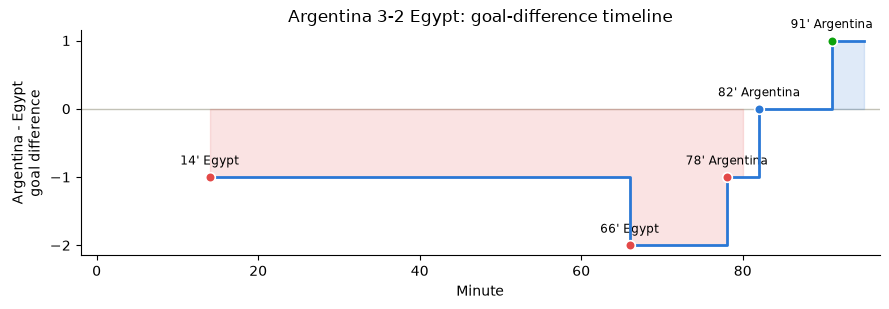

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.2))
minutes = checkpoints["minute"].tolist()
diffs = checkpoints["argentina_goal_difference"].tolist()

ax.step(minutes, diffs, where="post", color="#2a78d6", linewidth=2, zorder=4)
ax.axhline(0, color="#c3c2b7", linewidth=1, zorder=1)
ax.fill_between(
    minutes, diffs, 0,
    where=[d < 0 for d in diffs], step="post", color="#e34948", alpha=0.15, zorder=2,
)
ax.fill_between(
    minutes, diffs, 0,
    where=[d > 0 for d in diffs], step="post", color="#2a78d6", alpha=0.15, zorder=2,
)

for _, goal in focal_goals.iterrows():
    minute = int(goal["elapsed_seconds"]) // 60
    diff = int(goal["score_argentina"]) - int(goal["score_egypt"])
    is_winner = goal["elapsed_seconds"] == focal_goals["elapsed_seconds"].max()
    color = "#0ca30c" if is_winner else ("#e34948" if diff < 0 else "#2a78d6")
    ax.scatter([minute], [diff], color=color, zorder=5, s=48, edgecolor="white", linewidth=1.2)
    ax.annotate(
        f"{minute}' {goal['team']}", (minute, diff),
        textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8.5,
    )

ax.set_xlabel("Minute")
ax.set_ylabel("Argentina - Egypt\ngoal difference")
ax.set_title("Argentina 3-2 Egypt: goal-difference timeline")
ax.set_yticks([-2, -1, 0, 1])
ax.set_xlim(-2, 97)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Incident ledger: claims first, counterfactuals only after validation

A disputed incident is not automatically entered into the model. The ledger records the claim, proposed alternate state, and current evidence status. `reported` incidents are shown for transparency but excluded from the primary counterfactual analysis. A validated alternate state requires a time-aligned event record and a documented decision-review rule.

The branch for a possible Egypt penalty never turns a no-call into a certain goal. A valid model must represent both penalty-scored and penalty-missed branches, use a documented conversion distribution, and carry the uncertainty forward.


In [8]:
from research_etl.counterfactual import check_incident_eligibility

incidents_path = DATA_PROCESSED / "incidents.csv"
if incidents_path.exists():
    incidents_raw = pd.read_csv(incidents_path)
    ledger_rows = []
    for _, incident in incidents_raw.iterrows():
        eligibility = check_incident_eligibility(incident)
        ledger_rows.append(
            {
                "incident_id": incident["incident_id"],
                "claim": incident["claim"],
                "actual_decision": incident["actual_decision"],
                "proposed_alternate": incident["alternate_decision"],
                "evidence_status": incident["evidence_status"],
                "primary_analysis_eligible": eligibility.eligible,
                "why_pending": "eligible" if eligibility.eligible else eligibility.reason,
            }
        )
    incident_ledger = pd.DataFrame(ledger_rows)
else:
    incident_ledger = pd.DataFrame(
        columns=[
            "incident_id", "claim", "actual_decision", "proposed_alternate",
            "evidence_status", "primary_analysis_eligible", "why_pending",
        ]
    )
    print("Pending: run the ETL pipeline to produce data/processed/incidents.csv before the incident ledger can be displayed.")

display(incident_ledger)

,incident_id,claim,actual_decision,proposed_alternate,evidence_status,primary_analysis_eligible,why_pending
0,INC_001,"Egypt forward Mostafa Zico, set up by Mohamed ...",goal disallowed for an offence in the build-up,goal stands; immediate score becomes Argentina...,reported,False,evidence_status='reported' is not eligible for...
1,INC_002,In the late-stage build-up before Argentina sc...,VAR checked both incidents and did not award a...,penalty awarded on one or both incidents; bran...,reported,False,evidence_status='reported' is not eligible for...
2,INC_003,Egypt made a separate penalty appeal earlier i...,no penalty awarded; incident and review status...,unknown; insufficient detail to define an alte...,unresolved,False,evidence_status='unresolved' is not eligible f...


## Historical rarity: fixed-threshold snapshots with uncertainty

The empirical estimate uses one state per match at each threshold. First reconstruct scores at `t:00`; then retain matches in which the eventual winner was trailing by at least two at that exact point. The target is the regulation-time outcome.

The function below assumes a prepared `historical_snapshots` table with one row per `match_id` and threshold. It computes the raw rate and a Wilson interval. This is the descriptive baseline. It must not be described as a match-specific forecast, and its denominator should always appear beside the percentage.


In [9]:
from statistics import NormalDist


def wilson_interval(successes: int, total: int, confidence: float = 0.95) -> tuple[float, float]:
    if total == 0:
        return (np.nan, np.nan)
    z = NormalDist().inv_cdf(1 - (1 - confidence) / 2)
    proportion = successes / total
    denominator = 1 + z**2 / total
    centre = (proportion + z**2 / (2 * total)) / denominator
    half_width = z * math.sqrt(
        proportion * (1 - proportion) / total + z**2 / (4 * total**2)
    ) / denominator
    return max(0.0, centre - half_width), min(1.0, centre + half_width)


def summarize_comeback_rarity(historical_snapshots: pd.DataFrame, threshold: int) -> pd.DataFrame:
    required = {"match_id", "threshold_minute", "goal_difference", "regulation_result"}
    missing = required - set(historical_snapshots.columns)
    if missing:
        raise ValueError(f"Historical snapshots missing columns: {sorted(missing)}")

    eligible = historical_snapshots.loc[
        historical_snapshots.threshold_minute.eq(threshold)
        & historical_snapshots.goal_difference.le(-2)
    ].drop_duplicates("match_id")
    wins = int(eligible.regulation_result.eq("TRAILING_TEAM_WIN").sum())
    total = int(len(eligible))
    lower, upper = wilson_interval(wins, total)
    return pd.DataFrame(
        [{
            "threshold_minute": threshold,
            "comeback_wins": wins,
            "eligible_matches": total,
            "empirical_probability": wins / total if total else np.nan,
            "wilson_lower": lower,
            "wilson_upper": upper,
        }]
    )


historical_path = DATA_PROCESSED / "historical_snapshots.csv"
if historical_path.exists():
    historical_snapshots = pd.read_csv(historical_path)
    rarity_table = pd.concat(
        [summarize_comeback_rarity(historical_snapshots, t) for t in (70, 75, 78, 80)],
        ignore_index=True,
    )
    rarity_display = rarity_table.copy()
    for column in ("empirical_probability", "wilson_lower", "wilson_upper"):
        rarity_display[column] = rarity_display[column].map(lambda value: f"{value:.2%}" if pd.notna(value) else "")
    display(rarity_display)
else:
    print(
        "Pending: build data/processed/historical_snapshots.csv from complete historical event timelines. "
        "No historical rarity percentage is reported until this file exists."
    )


,threshold_minute,comeback_wins,eligible_matches,empirical_probability,wilson_lower,wilson_upper
0,70,0,278,0.00%,0.00%,1.36%
1,75,0,292,0.00%,0.00%,1.30%
2,78,0,300,0.00%,0.00%,1.26%
3,80,0,316,0.00%,0.00%,1.20%


### Historical continuation probability (visual)

For each real match state Argentina was actually in, this asks the same question as the rarity table above but at the exact minute and goal difference, using the comparable-historical-state lookup from `research_etl.counterfactual` (Project.md S7.4). It is descriptive, not the calibrated model from Stage C.

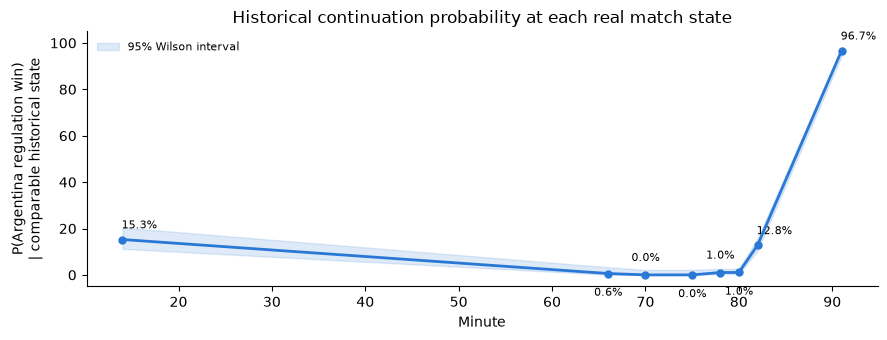

,minute,argentina_goal_difference,eligible_matches,eligible_team_states,interval_method,wins,draws,losses,p_win,wilson_lower,wilson_upper
0,14,-1,236,236,wilson_match_level,36,51,149,15.25%,11.23%,20.39%
1,66,-2,167,167,wilson_match_level,1,8,158,0.60%,0.11%,3.31%
2,70,-2,174,174,wilson_match_level,0,6,168,0.00%,0.00%,2.16%
3,75,-2,172,172,wilson_match_level,0,3,169,0.00%,0.00%,2.18%
4,78,-1,388,388,wilson_match_level,4,55,329,1.03%,0.40%,2.62%
5,80,-1,381,381,wilson_match_level,4,51,326,1.05%,0.41%,2.67%
6,82,0,266,532,match_cluster_bootstrap,68,396,68,12.78%,10.34%,15.60%
7,91,1,360,360,wilson_match_level,348,12,0,96.67%,94.26%,98.08%


In [10]:
from research_etl.counterfactual import continuation_probability

historical_events_path_for_chart = DATA_PROCESSED / "historical_match_events.csv"

if historical_path.exists() and historical_events_path_for_chart.exists():
    historical_events_for_chart = pd.read_csv(historical_events_path_for_chart)
    checkpoint_states = [(14, -1), (66, -2), (70, -2), (75, -2), (78, -1), (80, -1), (82, 0), (91, 1)]

    win_prob_rows = []
    for minute, goal_difference in checkpoint_states:
        estimate = continuation_probability(
            historical_events_for_chart, historical_snapshots,
            elapsed_seconds=minute * 60, goal_difference=goal_difference,
        )
        win_prob_rows.append(
            {
                "minute": minute,
                "argentina_goal_difference": goal_difference,
                "eligible_matches": estimate.eligible_matches,
                "eligible_team_states": estimate.eligible_team_states,
                "interval_method": estimate.interval_method,
                "wins": estimate.wins,
                "draws": estimate.draws,
                "losses": estimate.losses,
                "p_win": estimate.p_win,
                "wilson_lower": estimate.wilson_lower,
                "wilson_upper": estimate.wilson_upper,
            }
        )
    win_prob_timeline = pd.DataFrame(win_prob_rows)

    fig, ax = plt.subplots(figsize=(9, 3.5))
    x = win_prob_timeline["minute"]
    y = win_prob_timeline["p_win"] * 100
    lo = win_prob_timeline["wilson_lower"] * 100
    hi = win_prob_timeline["wilson_upper"] * 100
    ax.plot(x, y, color="#2a78d6", linewidth=2, marker="o", markersize=5, zorder=5)
    ax.fill_between(x, lo, hi, color="#2a78d6", alpha=0.15, label="95% Wilson interval")
    crowded_minutes = {66, 70, 75, 78, 80}
    for position, row in enumerate(win_prob_timeline.itertuples()):
        offset = (12, 8) if row.minute not in crowded_minutes else ((0, -16) if position % 2 else (0, 10))
        ax.annotate(
            f"{row.p_win:.1%}", (row.minute, row.p_win * 100),
            textcoords="offset points", xytext=offset, ha="center", fontsize=8,
        )
    ax.set_xlabel("Minute")
    ax.set_ylabel("P(Argentina regulation win)\n| comparable historical state")
    ax.set_title("Historical continuation probability at each real match state")
    ax.set_ylim(-5, 105)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper left", frameon=False, fontsize=8)
    plt.tight_layout()
    plt.show()

    win_prob_display = win_prob_timeline.copy()
    for column in ("p_win", "wilson_lower", "wilson_upper"):
        win_prob_display[column] = win_prob_display[column].map(lambda value: f"{value:.2%}" if pd.notna(value) else "")
    display(win_prob_display)
else:
    print("Pending: run the ETL pipeline before the win-probability timeline chart can be drawn.")

## Stage C validation and support-limited focal probabilities

The model uses elapsed time, goal difference, red-card difference, pre-match Elo difference, knockout status, and neutral-site status. Validation keeps complete matches separate across match-grouped, tournament-grouped, chronological, and inner calibration splits.

Passing global calibration is necessary but not sufficient. Every focal checkpoint is also checked against a local neighborhood of historical matches with similar time, score difference, and strength difference. Sparse states remain `extrapolative_low_support` even when the selected model passes global validation.

In [11]:
model_validation_path = RESULTS_DIR / "model_validation.json"
if model_validation_path.exists():
    model_validation = load_json_if_present(model_validation_path)
    print("Validation status:", model_validation["status"])
    print("Selected model:", model_validation["selected_model"])
    print("Focal probability status:", model_validation["focal_probability_status"])

    check_rows = []
    metric_rows = []
    for model_name, model_result in model_validation["models"].items():
        for check, passed in model_result["checks"].items():
            check_rows.append({"model": model_name, "check": check, "passed": passed})
        for split_name, values in model_result["metrics"].items():
            metric_rows.append(
                {
                    "model": model_name,
                    "split": split_name,
                    "rows": values["rows"],
                    "log_loss": values["log_loss"],
                    "multiclass_brier": values["multiclass_brier"],
                    "max_class_ece": values["max_class_ece"],
                }
            )
    display(pd.DataFrame(check_rows))
    display(pd.DataFrame(metric_rows))

    focal_model_path = RESULTS_DIR / "focal_model_probabilities.csv"
    if focal_model_path.exists():
        focal_model_probabilities = pd.read_csv(focal_model_path)
        focal_display = focal_model_probabilities[
            [
                "minute", "score_argentina", "score_egypt", "p_focal_win", "p_draw", "p_focal_loss",
                "p_focal_win_ensemble_min", "p_focal_win_ensemble_max",
                "local_support_matches", "support_status", "probability_status",
            ]
        ].copy()
        for column in (
            "p_focal_win", "p_draw", "p_focal_loss",
            "p_focal_win_ensemble_min", "p_focal_win_ensemble_max",
        ):
            focal_display[column] = focal_display[column].map(lambda value: f"{value:.2%}")
        display(focal_display)
else:
    print("Pending: run `uv run --project . python -m research_etl analyze`.")

Validation status: passed
Selected model: calibrated_hist_gradient_boosting
Focal probability status: exploratory_support_limited


,model,check,passed
0,calibrated_hist_gradient_boosting,chronological_brier_beats_null,True
1,calibrated_hist_gradient_boosting,late_game_ece_within_gate,True
2,calibrated_hist_gradient_boosting,match_brier_beats_null,True
3,calibrated_hist_gradient_boosting,overall_ece_within_gate,True
4,calibrated_hist_gradient_boosting,tournament_brier_beats_null,True
5,multinomial_logistic,chronological_brier_beats_null,True
6,multinomial_logistic,late_game_ece_within_gate,False
7,multinomial_logistic,match_brier_beats_null,True
8,multinomial_logistic,overall_ece_within_gate,True
9,multinomial_logistic,tournament_brier_beats_null,True


,model,split,rows,log_loss,multiclass_brier,max_class_ece
0,calibrated_hist_gradient_boosting,chronological_holdout,11520,0.908925,0.486102,0.053505
1,calibrated_hist_gradient_boosting,chronological_null,11520,1.076528,0.652723,0.022292
2,calibrated_hist_gradient_boosting,match_grouped_late_game,40488,0.510641,0.283817,0.072355
3,calibrated_hist_gradient_boosting,match_grouped_null,173520,1.084588,0.657712,0.000005
4,calibrated_hist_gradient_boosting,match_grouped_oof,173520,0.812529,0.472253,0.034002
5,calibrated_hist_gradient_boosting,tournament_grouped_null,173520,1.084676,0.657763,0.000218
6,calibrated_hist_gradient_boosting,tournament_grouped_oof,173520,0.821839,0.477146,0.028450
7,multinomial_logistic,chronological_holdout,11520,0.878583,0.493834,0.065898
8,multinomial_logistic,chronological_null,11520,1.076528,0.652723,0.022292
9,multinomial_logistic,match_grouped_late_game,40488,0.505194,0.289190,0.124984


,minute,score_argentina,score_egypt,p_focal_win,p_draw,p_focal_loss,p_focal_win_ensemble_min,p_focal_win_ensemble_max,local_support_matches,support_status,probability_status
0,14,0,1,56.75%,30.29%,12.95%,30.61%,71.65%,13,extrapolative_low_support,exploratory_support_limited
1,66,0,2,16.67%,25.97%,57.36%,1.89%,29.14%,3,extrapolative_low_support,exploratory_support_limited
2,70,0,2,16.14%,26.20%,57.67%,1.78%,28.23%,2,extrapolative_low_support,exploratory_support_limited
3,75,0,2,11.73%,26.54%,61.73%,1.52%,24.29%,1,extrapolative_low_support,exploratory_support_limited
4,78,1,2,12.90%,43.46%,43.64%,6.75%,26.19%,14,extrapolative_low_support,exploratory_support_limited
5,80,1,2,12.43%,43.34%,44.23%,6.75%,24.68%,14,extrapolative_low_support,exploratory_support_limited
6,82,2,2,36.11%,58.60%,5.29%,26.64%,46.39%,37,supported,exploratory_support_limited
7,91,3,2,85.44%,13.79%,0.77%,78.85%,93.34%,28,supported,exploratory_support_limited


## Counterfactual simulation: branching rather than replaying the match

A counterfactual starts at a verified incident time and changes only the state implied by the alternate decision. Remaining goals are simulated from a fitted distribution; Argentina's actual late goals are not replayed. This makes the estimate conditional and auditable.

For a possible penalty, the simulation branches over conversion uncertainty. The illustrative range below is intentionally broad and must be replaced by a cited tournament-specific empirical distribution before conclusions are drawn. An unvalidated incident remains excluded from the primary output.


In [12]:
@dataclass(frozen=True)
class CounterfactualScenario:
    scenario_id: str
    elapsed_seconds: int | None
    actual_score: tuple[int, int] | None
    alternate_score: tuple[int, int] | None
    evidence_status: str
    description: str


SCENARIOS = [
    CounterfactualScenario(
        scenario_id="observed_record",
        elapsed_seconds=None,
        actual_score=(3, 2),
        alternate_score=(3, 2),
        evidence_status="officially_confirmed",
        description="Observed final record; used for reconciliation, not a causal comparison.",
    ),
    CounterfactualScenario(
        scenario_id="disallowed_egypt_goal_stands",
        elapsed_seconds=None,
        actual_score=(0, 1),
        alternate_score=(0, 2),
        evidence_status="reported",
        description="Eligible only after the exact incident time and alternative decision are validated.",
    ),
    CounterfactualScenario(
        scenario_id="egypt_penalty_awarded",
        elapsed_seconds=None,
        actual_score=None,
        alternate_score=None,
        evidence_status="reported",
        description="Branches over a documented penalty conversion distribution after validation.",
    ),
]


def penalty_branch_weights(conversion_grid: Iterable[float]) -> pd.DataFrame:
    values = np.asarray(list(conversion_grid), dtype=float)
    if values.size == 0 or np.any((values <= 0) | (values >= 1)):
        raise ValueError("Conversion probabilities must be strictly between 0 and 1.")
    return pd.DataFrame(
        {
            "penalty_conversion_probability": values,
            "score_branch_weight": values,
            "miss_branch_weight": 1 - values,
        }
    )


penalty_sensitivity = penalty_branch_weights(np.arange(0.70, 0.851, 0.025))
display(pd.DataFrame([scenario.__dict__ for scenario in SCENARIOS]))
penalty_display = penalty_sensitivity.copy()
for column in ("penalty_conversion_probability", "score_branch_weight", "miss_branch_weight"):
    penalty_display[column] = penalty_display[column].map(lambda value: f"{value:.1%}")
display(penalty_display)


,scenario_id,elapsed_seconds,actual_score,alternate_score,evidence_status,description
0,observed_record,None,"(3, 2)","(3, 2)",officially_confirmed,Observed final record; used for reconciliation...
1,disallowed_egypt_goal_stands,None,"(0, 1)","(0, 2)",reported,Eligible only after the exact incident time an...
2,egypt_penalty_awarded,None,None,None,reported,Branches over a documented penalty conversion ...


,penalty_conversion_probability,score_branch_weight,miss_branch_weight
0,70.0%,70.0%,30.0%
1,72.5%,72.5%,27.5%
2,75.0%,75.0%,25.0%
3,77.5%,77.5%,22.5%
4,80.0%,80.0%,20.0%
5,82.5%,82.5%,17.5%
6,85.0%,85.0%,15.0%


## Stage D: scenario-only conditional timing sensitivity

Manual correctness review is intentionally deferred. The analysis below does not decide whether the disallowed goal should have stood. It asks a narrower question: **if** the immediate state is changed from Argentina 0-1 Egypt to Argentina 0-2 Egypt at one of the reported times, how does the historical regulation-win probability change?

The 58/62/67-minute assumptions are evaluated separately. Output is labelled `exploratory_conditional`, uncertainty is bootstrapped by historical match, and `decision_correctness_status` remains `not_assessed`. Reported penalty incidents remain pending because their timing and alternate states are not sufficiently defined.

In [13]:
from research_etl.counterfactual import check_incident_eligibility

incidents_path = DATA_PROCESSED / "incidents.csv"
if incidents_path.exists():
    incidents_for_cf = pd.read_csv(incidents_path)
    eligibility_rows = []
    for _, incident in incidents_for_cf.iterrows():
        eligibility = check_incident_eligibility(incident)
        eligibility_rows.append(
            {
                "incident_id": eligibility.incident_id,
                "correctness_assessed_primary_eligible": eligibility.eligible,
                "reason": eligibility.reason,
            }
        )
    display(pd.DataFrame(eligibility_rows))
else:
    print("Pending: incidents.csv is unavailable.")

scenario_path = RESULTS_DIR / "scenario_only_counterfactual.csv"
if scenario_path.exists():
    scenario_results = pd.read_csv(scenario_path)
    scenario_display = scenario_results[
        [
            "scenario_id", "timing_minute", "analysis_status", "decision_correctness_status",
            "observed_p_win", "alternate_p_win", "impact_percentage_points",
            "bootstrap_lower_percentage_points", "bootstrap_upper_percentage_points",
            "observed_eligible_matches", "alternate_eligible_matches", "assumption",
        ]
    ].copy()
    for column in ("observed_p_win", "alternate_p_win"):
        scenario_display[column] = scenario_display[column].map(lambda value: f"{value:.2%}")
    for column in (
        "impact_percentage_points", "bootstrap_lower_percentage_points", "bootstrap_upper_percentage_points"
    ):
        scenario_display[column] = scenario_display[column].map(lambda value: f"{value:.2f} pp")
    display(scenario_display)
else:
    print("Pending: run `uv run --project . python -m research_etl analyze` for scenario-only results.")

,incident_id,correctness_assessed_primary_eligible,reason
0,INC_001,False,evidence_status='reported' is not eligible for...
1,INC_002,False,evidence_status='reported' is not eligible for...
2,INC_003,False,evidence_status='unresolved' is not eligible f...


,scenario_id,timing_minute,analysis_status,decision_correctness_status,observed_p_win,alternate_p_win,impact_percentage_points,bootstrap_lower_percentage_points,bootstrap_upper_percentage_points,observed_eligible_matches,alternate_eligible_matches,assumption
0,INC_001_DISALLOWED_GOAL_STANDS,58.0,exploratory_conditional,not_assessed,5.84%,0.70%,5.13 pp,2.39 pp,7.83 pp,394,142,Conditional timing grid based on conflicting p...
1,INC_001_DISALLOWED_GOAL_STANDS,62.0,exploratory_conditional,not_assessed,5.68%,0.65%,5.04 pp,2.40 pp,7.69 pp,387,155,Conditional timing grid based on conflicting p...
2,INC_001_DISALLOWED_GOAL_STANDS,67.0,exploratory_conditional,not_assessed,3.62%,0.60%,3.02 pp,0.84 pp,5.33 pp,387,167,Conditional timing grid based on conflicting p...


## Stage E (exploratory, not pre-registered): team-level discipline outlier check

This section responds to a separate public narrative -- that Argentina has received unusually favourable officiating since the 2022 World Cup. It is explicitly exploratory and was not pre-registered before the historical data was inspected (unlike the Stage A rarity thresholds), so it is a prompt for further investigation, not a confirmatory test.

**What it can show:** for each men's World Cup edition, how a team's yellow cards, red cards, and *scored* penalty goals per match compare to the rest of that edition's field (percentile rank), and how that has moved across editions for one team.

**What it cannot show:** it does not control for possession share, opponent quality, scoreline context (teams trailing tend to foul more), or which referee was assigned -- all of which legitimately shift these raw counts without implying favourable treatment. A high percentile here is evidence something is worth investigating further, not evidence of bias (Project.md S4, S5.5, S8).

**Data limits:** fouls, offsides, and VAR-check counts are not available in any currently integrated source for any edition. Scored penalty goals are available for men's World Cups 1930-2022 from the Fjelstul database. Yellow and red cards only exist in that source from **1970 onward** (the card system was not used before then, so every team shows 0 pre-1970 -- those editions are excluded from the card percentile scan below to avoid a tied-at-zero field reading as a false 100th percentile). 2026 is not yet in that historical database.

In [14]:
from research_etl.discipline import percentile_rank, team_history, team_tournament_discipline

fjelstul_dir = PROJECT_ROOT / "data" / "raw" / "fjelstul"

if (fjelstul_dir / "matches.csv").exists():
    raw_matches = pd.read_csv(fjelstul_dir / "matches.csv")
    raw_goals = pd.read_csv(fjelstul_dir / "goals.csv")
    raw_bookings = pd.read_csv(fjelstul_dir / "bookings.csv")
    discipline = team_tournament_discipline(raw_matches, raw_goals, raw_bookings)

    argentina_history = team_history(discipline, "Argentina")
    display(
        argentina_history[
            [
                "tournament_name", "year", "matches_played", "yellow_cards", "red_cards",
                "penalty_goals_scored", "yellow_cards_per_match", "red_cards_per_match",
                "penalty_goals_scored_per_match",
            ]
        ]
    )
else:
    print("Pending: Fjelstul raw source files (data/raw/fjelstul/) not found. Run the ETL pipeline first.")

,tournament_name,year,matches_played,yellow_cards,red_cards,penalty_goals_scored,yellow_cards_per_match,red_cards_per_match,penalty_goals_scored_per_match
0,1930 FIFA Men's World Cup,1930,5,0,0,0,0.000000,0.000000,0.000000
1,1934 FIFA Men's World Cup,1934,1,0,0,0,0.000000,0.000000,0.000000
2,1958 FIFA Men's World Cup,1958,3,0,0,2,0.000000,0.000000,0.666667
3,1962 FIFA Men's World Cup,1962,3,0,0,0,0.000000,0.000000,0.000000
4,1966 FIFA Men's World Cup,1966,4,0,0,0,0.000000,0.000000,0.000000
5,1974 FIFA Men's World Cup,1974,6,8,0,0,1.333333,0.000000,0.000000
6,1978 FIFA Men's World Cup,1978,7,4,0,1,0.571429,0.000000,0.142857
7,1982 FIFA Men's World Cup,1982,5,7,2,1,1.400000,0.400000,0.200000
8,1986 FIFA Men's World Cup,1986,7,12,0,0,1.714286,0.000000,0.000000
9,1990 FIFA Men's World Cup,1990,7,22,3,0,3.142857,0.428571,0.000000


### Where does Argentina sit within each edition's field?

For every edition Argentina played, this computes their percentile rank against every other team in that same tournament (higher = more of that metric than most of the field). This directly tests "is 2022 unusual" both against Argentina's own history and against the field they were actually competing in that year -- without needing to pick one specific rival team as the comparison.

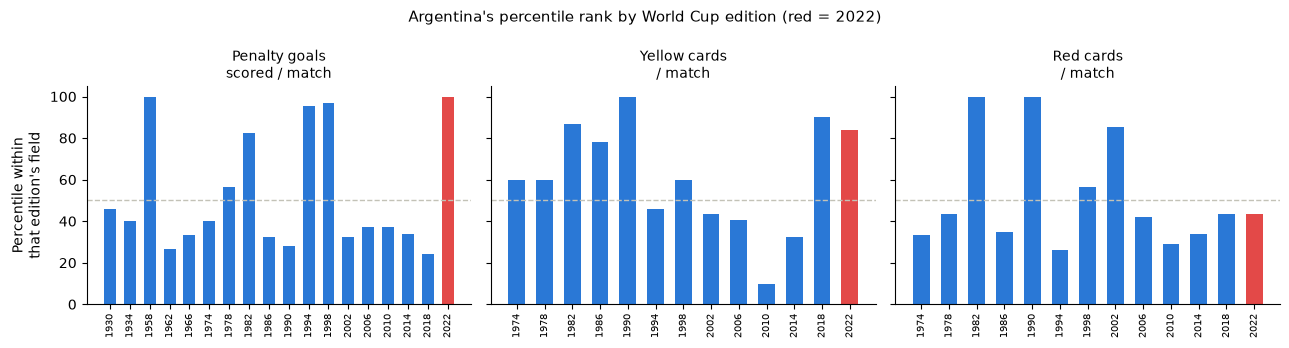

metric,penalty_goals_scored_per_match,red_cards_per_match,yellow_cards_per_match
year,,,
1930,46%,,
1934,40%,,
1958,100%,,
1962,27%,,
1966,33%,,
1974,40%,33%,60%
1978,57%,43%,60%
1982,83%,100%,87%
1986,33%,35%,78%


In [15]:
if (fjelstul_dir / "matches.csv").exists():
    percentile_rows = []
    cards_tracked_from_year = 1970  # yellow/red cards were introduced at the 1970 World Cup;
    # bookings.csv has zero rows before that, so a pre-1970 card percentile would trivially read
    # 100% (everyone tied at 0) and misrepresent "no data" as "most cards in the field".
    for _, row in argentina_history.iterrows():
        metrics = ["penalty_goals_scored_per_match"]
        if row["year"] >= cards_tracked_from_year:
            metrics += ["yellow_cards_per_match", "red_cards_per_match"]
        for metric in metrics:
            result = percentile_rank(discipline, row["tournament_name"], "Argentina", metric)
            percentile_rows.append(
                {
                    "year": row["year"],
                    "metric": metric,
                    "value": result["value"],
                    "field_size": result["field_size"],
                    "field_median": result["field_median"],
                    "percentile": result["percentile"],
                }
            )
    percentile_table = pd.DataFrame(percentile_rows)

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
    metric_labels = {
        "penalty_goals_scored_per_match": "Penalty goals\nscored / match",
        "yellow_cards_per_match": "Yellow cards\n/ match",
        "red_cards_per_match": "Red cards\n/ match",
    }
    for ax, (metric, label) in zip(axes, metric_labels.items()):
        subset = percentile_table.loc[percentile_table["metric"].eq(metric)]
        colors = ["#e34948" if year == 2022 else "#2a78d6" for year in subset["year"]]
        ax.bar(subset["year"].astype(str), subset["percentile"] * 100, color=colors, width=0.6)
        ax.axhline(50, color="#c3c2b7", linewidth=1, linestyle="--")
        ax.set_title(label, fontsize=10)
        ax.set_ylim(0, 105)
        ax.tick_params(axis="x", labelrotation=90, labelsize=7)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].set_ylabel("Percentile within\nthat edition's field")
    fig.suptitle("Argentina's percentile rank by World Cup edition (red = 2022)", fontsize=11)
    plt.tight_layout()
    plt.show()

    display(
        percentile_table.pivot(index="year", columns="metric", values="percentile")
        .map(lambda value: f"{value:.0%}" if pd.notna(value) else "")
    )
else:
    print("Pending: Fjelstul raw source files not found.")

### Reading the percentile chart

Argentina's 2022 penalty-goal rate is the unique maximum in that edition and its yellow-card rate is relatively high. Argentina recorded **zero red cards**; with 28 of 32 teams tied at zero, the tie-aware red-card percentile is approximately 44%, not 88%.

The edition history does not show a clean raw-count break beginning in 2022: Argentina also reached the top penalty-goal rank in 1958, while several earlier editions had higher card rates. This supports only a descriptive statement about counts. It does not test preferential treatment because possession, penalty-area exposure, foul/challenge exposure, opponent quality, and referee assignment are not controlled.

### 2026 (in progress): penalties awarded so far

A second, independent check on the same "golden child since 2022" narrative, using the FIFA Post-Match Summary Report's official "Set Plays" table for every 2026 World Cup match played through the Round of 16 (96 of 96 matches -- a full census at time of retrieval, not a sample; extraction method and per-match source URLs are in `config/sources.json:pmsr_2026` and `data/raw/fifa/pmsr_2026_set_plays_extracted.csv`).

**This is a different metric than the 1930-2022 chart above and must not be merged with it or averaged into one number:**
- 1930-2022 (Fjelstul): *penalty goals scored* -- only converted penalties.
- 2026 (FIFA PMSR): *penalties awarded* -- includes scored, saved, and missed kicks. Messi's minute-20 penalty against Egypt (saved, not scored -- see above) counts here.

Teams have played between 3 and 5 matches depending on how far they advanced, so this is reported as a rate (per match), not a raw count, and it reflects one in-progress tournament, not 22 completed ones.

Argentina: 0.60 penalties awarded per match (3 in 5 matches), 100% percentile of a 48-team field (field median 0.00).


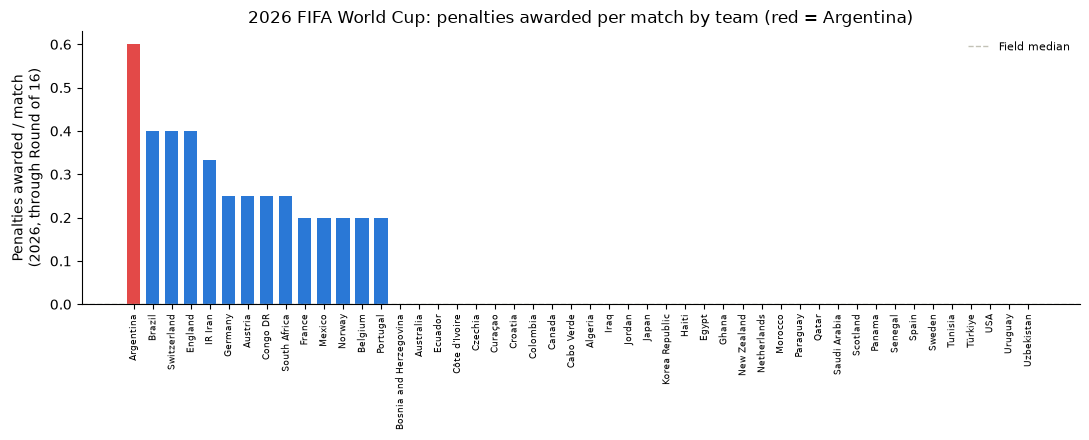

,tournament_name,year,team_name,matches_played,penalties_awarded,penalties_awarded_per_match
0,2026 FIFA World Cup,2026,Argentina,5,3,0.600000
1,2026 FIFA World Cup,2026,Brazil,5,2,0.400000
2,2026 FIFA World Cup,2026,Switzerland,5,2,0.400000
3,2026 FIFA World Cup,2026,England,5,2,0.400000
4,2026 FIFA World Cup,2026,IR Iran,3,1,0.333333
5,2026 FIFA World Cup,2026,Germany,4,1,0.250000
6,2026 FIFA World Cup,2026,Austria,4,1,0.250000
7,2026 FIFA World Cup,2026,Congo DR,4,1,0.250000
8,2026 FIFA World Cup,2026,South Africa,4,1,0.250000
9,2026 FIFA World Cup,2026,France,5,1,0.200000


In [16]:
pmsr_2026_path = DATA_PROCESSED / "pmsr_2026_team_penalties.csv"

if pmsr_2026_path.exists():
    pmsr_2026 = pd.read_csv(pmsr_2026_path)
    argentina_2026 = percentile_rank(pmsr_2026, "2026 FIFA World Cup", "Argentina", "penalties_awarded_per_match")
    arg_row = pmsr_2026.loc[pmsr_2026.team_name.eq("Argentina")].iloc[0]
    print(
        f"Argentina: {arg_row.penalties_awarded_per_match:.2f} penalties awarded per match "
        f"({int(arg_row.penalties_awarded)} in {int(arg_row.matches_played)} matches), "
        f"{argentina_2026['percentile']:.0%} percentile of a {argentina_2026['field_size']}-team field "
        f"(field median {argentina_2026['field_median']:.2f})."
    )

    field_sorted = pmsr_2026.sort_values("penalties_awarded_per_match", ascending=False).reset_index(drop=True)
    colors = ["#e34948" if team == "Argentina" else "#2a78d6" for team in field_sorted["team_name"]]

    fig, ax = plt.subplots(figsize=(11, 4.5))
    ax.bar(field_sorted["team_name"], field_sorted["penalties_awarded_per_match"], color=colors, width=0.7)
    ax.axhline(argentina_2026["field_median"], color="#c3c2b7", linewidth=1, linestyle="--", label="Field median")
    ax.set_ylabel("Penalties awarded / match\n(2026, through Round of 16)")
    ax.set_title("2026 FIFA World Cup: penalties awarded per match by team (red = Argentina)")
    ax.tick_params(axis="x", labelrotation=90, labelsize=6.5)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper right", frameon=False, fontsize=8)
    plt.tight_layout()
    plt.show()

    display(field_sorted)
else:
    print(
        "Pending: data/processed/pmsr_2026_team_penalties.csv not found. "
        "See config/sources.json:pmsr_2026 for the extraction method and source URLs."
    )

### Reading the 2026 chart

Argentina currently leads this field outright: 3 penalties awarded in 5 matches (0.60/match), just above Brazil, Switzerland, and England (0.40/match each), against a field median of 0.00 -- most teams in this 48-team, expanded-format tournament have not been awarded a single penalty through the Round of 16 (matches played range 3-5 depending on how far a team advanced, so small absolute counts move the rate a lot).

This is a single in-progress tournament with the smallest sample of any comparison in this notebook (48 teams, 3-5 matches each) -- it cannot by itself establish or refute a multi-year pattern, and it carries the same confounds as the 1930-2022 chart above (possession share, time spent in the opponent's box, playing style, opponent quality; Project.md S4, S5.5, S8). Read together with the 1930-2022 percentile chart, it is a second directional data point pointing the same way as 2022, not independent proof of anything: both are equally consistent with "a squad that spends a lot of time in the opposition box draws more penalty shouts," which matches Argentina's actual profile across this period (an elite, heavily attacking, ball-dominant side) as well as it matches any preferential-treatment story.

## Results status and reporting checklist

Current evidence supports a descriptive rarity result and an exploratory conditional scenario. It does not yet support decision correctness, a calibrated focal forecast, systematic bias, corruption, or intent.

Before publication of stronger conclusions:

- preserve source manifests and checksums;
- resolve or explicitly defer material incidents;
- show unique-match denominators and interval methods;
- preserve the passed model gate while adding preregistered validation;
- flag or resolve focal checkpoints with low local historical support;
- add broader-sample and era sensitivity;
- keep every scenario conditional on its stated assumptions.

In [17]:
model_gate_passed = False
focal_strength_ready = (DATA_PROCESSED / "focal_pre_match_strength.csv").exists()
focal_support_ready = False
if (RESULTS_DIR / "model_validation.json").exists():
    current_validation = load_json_if_present(RESULTS_DIR / "model_validation.json")
    model_gate_passed = current_validation["status"] == "passed"
if (RESULTS_DIR / "focal_model_probabilities.csv").exists():
    current_focal = pd.read_csv(RESULTS_DIR / "focal_model_probabilities.csv")
    focal_support_ready = current_focal["support_status"].eq("supported").all()

completion_checklist = pd.DataFrame(
    [
        ("Focal counted-goal timeline reconciled to Tier A source", True),
        ("Material decision correctness assessed", False),
        ("Historical coverage and denominator documented", historical_path.exists()),
        ("Tie-aware discipline percentile implemented", True),
        ("Scenario-only timing assumptions and bootstrap published", scenario_path.exists()),
        ("Calibrated secondary model passes engineering gate", model_gate_passed),
        ("Focal pre-kickoff 2026 strength available", focal_strength_ready),
        ("Every focal checkpoint has adequate local support", focal_support_ready),
        ("Conclusion limited to available evidence", True),
    ],
    columns=["requirement", "complete"],
)

substantive_ready = model_gate_passed and focal_strength_ready and focal_support_ready
print(f"Engineering/research checklist complete: {completion_checklist.complete.mean():.0%}")
print("Substantive focal-model readiness:", "ready" if substantive_ready else "support-limited")
display(completion_checklist)

Engineering/research checklist complete: 78%
Substantive focal-model readiness: support-limited


,requirement,complete
0,Focal counted-goal timeline reconciled to Tier...,True
1,Material decision correctness assessed,False
2,Historical coverage and denominator documented,True
3,Tie-aware discipline percentile implemented,True
4,Scenario-only timing assumptions and bootstrap...,True
5,Calibrated secondary model passes engineering ...,True
6,Focal pre-kickoff 2026 strength available,True
7,Every focal checkpoint has adequate local support,False
8,Conclusion limited to available evidence,True
